In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# --- 1. Chargement des données ---
# Dataset de classification binaire (détection de tumeurs malignes ou bénignes)
data = load_breast_cancer()
X, y = data.data, data.target

# --- 2. Séparation train/test ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- 3. Initialisation du modèle avec hyperparamètres ajustables ---
# Contrairement au modèle simple, on configure ici des paramètres clés qui pilotent l'apprentissage
model_advanced = GradientBoostingClassifier(
    n_estimators=100,  # Nombre d'arbres construits séquentiellement
    learning_rate=0.1,  # Vitesse d'apprentissage (taille des pas correctifs)
    max_depth=3,  # Profondeur maximale de chaque arbre de décision
    subsample=0.8,  # Fraction des données utilisées pour entraîner chaque arbre
    random_state=42,
)

# --- 4. Entraînement ---
model_advanced.fit(X_train, y_train)

# --- 5. Prédictions ---
y_pred = model_advanced.predict(X_test)

# --- 6. Évaluation ---
accuracy = accuracy_score(y_test, y_pred)
print(f"Précision globale du modèle (Accuracy) : {accuracy:.4f}")
print("\n--- Rapport détaillé de classification ---\n")
print(classification_report(y_test, y_pred))

Précision globale du modèle (Accuracy) : 0.9561

--- Rapport détaillé de classification ---

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        43
           1       0.96      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



<Figure size 600x600 with 0 Axes>

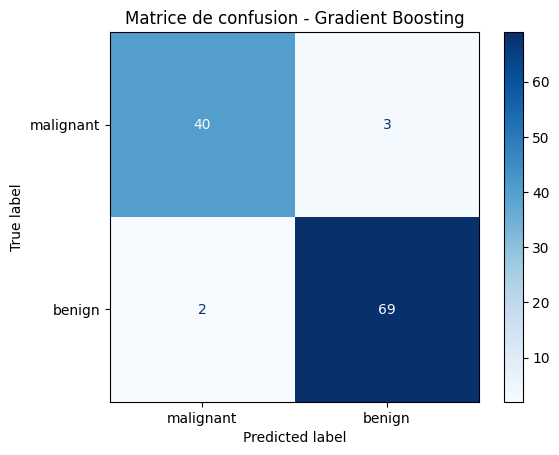

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- Visualisation : Matrice de confusion ---
plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    model_advanced,
    X_test,
    y_test,
    display_labels=data.target_names,
    cmap=plt.cm.Blues,
    values_format="d",
)
plt.title("Matrice de confusion - Gradient Boosting")
plt.grid(False)  # Désactive la grille pour un rendu plus net
plt.show()